In [1]:
import pandas as pd
import psycopg2
from psycopg2 import sql
import jinja2
import pdfkit
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import table
import json
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('../scripts/', '.')))

import argparse
from datetime import datetime, timedelta, date

from reportTools.importForwardingHist import importForwardingHistory
from reportTools.createReport import createReport
from reportTools.createGrowthReport import createGrowthReport
from reportTools.importChannelInfo import importChannelInfo

In [59]:
pd.to_datetime("today", utc=True) - pd.to_datetime(round((datetime.now() - timedelta(seconds=int('186429'))).timestamp()), utc=True, unit='s')

Timedelta('1 days 20:47:08.912014')

In [ ]:
today = pd.to_datetime("today", utc=True)
df_chan_age['age_days'] = today - pd.to_datetime(df_chan_age['timestamp_ns'], utc=True, unit='s')

In [43]:
timedelta(seconds=int('1649109276')).toDateTime()

AttributeError: 'datetime.timedelta' object has no attribute 'toDateTime'

In [21]:
int('175343')1649108323736

175343

In [44]:
datetime.fromtimestamp(1649109276)

datetime.datetime(2022, 4, 4, 14, 54, 36)

In [2]:
# Import Forwarding History

# via RPC

# via File Path

In [3]:
# Import Channel Info via RPC

# Import Active Channels

# Import Closed Channels

In [4]:
# Create Regular Report (Forwarding History + Channel Info)

In [5]:
# Create Growth Report (Forwarding History + Channel Info)

In [6]:
#example args
start_date = '12-01-2021'
end_date = date.today().strftime("%m-%d-%Y")
template_path = "fhreport_template.html"
create_csv = True
create_html = True
report_out_path = "."
debug = True

In [7]:
#import forwarding history
importfh = importForwardingHistory("lqwd-lnd", 8080, None, True)
createfh_report = createReport(start_date, end_date, template_path, create_csv, create_html, report_out_path, debug)

In [8]:
df, df_chan_age = createfh_report.get_forwarding_history_data("lnd-885")
final_df = createfh_report.build_dataframe(df, df_chan_age)

Get Forwarding History for Report Start Date: 12-01-2021, End Date: 02-15-2022
<class 'str'>
Connected to DB - <connection object at 0x113b46580; dsn: 'user=postgres password=xxx dbname=lnd host=192.168.113.250 port=5433', closed: 0>
Retreived Data from DB for LND - lnd-885 between Start Date: 12-01-2021, End Date: 02-15-2022
Rows: 1468
Building Dataframe for CSV and HTML output
CSV created - ./forwarding-history-report_12-12-2021_to_02-15-2022.csv


In [9]:
#this is loading chanel info via file but can be done using RPC
f_channels = open("listchannels_Jan31_2022.txt")
channel_json = json.load(f_channels)

In [10]:
# for data in channel_json['channels']:
#     print(data)

In [11]:
# import channel info
importci = importChannelInfo("lqwd-lnd", 8080, None, True)
channel_info_list = importci.handle_channel_info_json(channel_json, "lnd-885")

In [12]:
importci.insert_channel_info(channel_info_list)

Successfully Inserted 83 Rows into DB


In [13]:
create_growth_report = createGrowthReport(df[:-1], "lnd-885", None, True)

In [14]:
channel_df = create_growth_report.get_channel_info()

Getting Channel Info - Row Selected: 83


In [15]:
create_growth_report.build_growth_df()

Getting Channel Info - Row Selected: 83


,amt_in,amt_out,channel_capacity,fees_msat
week1,7202002991,7201961803,31421001,41188
week2,15365375684,15365244368,3000000,131316
week3,30091797959,30091654904,32085331,143055
week4,25368860007,25368718652,16681597,141355
week5,55738168167,55737767457,66500000,400710
week6,84660575594,84658226761,107000000,2348833
week7,131025234563,131024783628,123640554,450935
week8,9729512457,9729457742,100977215,54715


In [16]:
channel_df['event_date'] = pd.to_datetime(channel_df['timestamp_ns'], unit='ms', utc=True).dt.date

In [105]:
channel_df = channel_df.groupby(['chan_id', 'event_date']).sum().reset_index()

In [106]:
channel_df.columns

Index(['chan_id', 'event_date', 'timestamp_ns', 'channel_capacity',
       'fee_per_kw'],
      dtype='object')

In [107]:
channel_df = channel_df.drop(columns=['timestamp_ns','fee_per_kw'])

In [108]:
channel_df

,chan_id,event_date,channel_capacity
0,781783553783562240,2021-12-15,100000
1,781839628895059970,2021-12-15,1500000
2,781920992781729792,2021-12-15,500000
3,781977067852595200,2021-12-15,2000000
4,783332765642326016,2021-12-15,21001
...,...,...,...
78,792672017402626049,2022-02-05,5000000
79,792687410604212225,2022-02-06,6200000
80,792762177405648896,2022-02-06,16777215
81,792866630944817152,2022-02-07,5000000


In [109]:
#loop in increments of weeks to end date to build change values per cahnnel for amt in
end_date = pd.to_datetime(date.today(), utc=True)
tmp_date1 = channel_df['event_date'].min()

channel_df_wkly = pd.DataFrame(channel_df[channel_df['event_date'] <= channel_df['event_date'].min()+pd.to_timedelta(7, unit='d')].groupby(['chan_id']).sum()['channel_capacity'])

In [110]:
channel_df[(channel_df['event_date'] > tmp_date) & (channel_df['event_date'] <= tmp_date2)]

,chan_id,event_date,channel_capacity
17,786165107643908096,2021-12-28,3000000


In [111]:
for i in range(1, round((channel_df['event_date'].max() - channel_df['event_date'].min()).days/7)+1):
    tmp_date = channel_df['event_date'].min()+pd.to_timedelta(i*7, unit='d')
    tmp_date2 = channel_df['event_date'].min()+pd.to_timedelta((i+1)*7, unit='d')
    if tmp_date2 > end_date:
        tmp_date2 = end_date

    channel_df_wkly = pd.merge(channel_df_wkly, channel_df[(channel_df['event_date'] > tmp_date) & (channel_df['event_date'] <= tmp_date2)]\
                    .groupby(['chan_id']).sum()['channel_capacity'], on=['chan_id'], how='outer')\
                    .rename(columns={'channel_capacity_x': f'week{i}', 'channel_capacity_y': f'week{i+1}'})

In [19]:
# create_growth_report.amt_out_growth()
pd.merge(pd.Series(create_growth_report.amt_in_growth().sum(), name='amt_in'), pd.Series(create_growth_report.amt_out_growth().sum(), name='amt_out'), how='outer', left_index=True, right_index=True)

,amt_in,amt_out
week1,7202002991,7201961803
week2,15365375684,15365244368
week3,30091797959,30091654904
week4,25368860007,25368718652
week5,55738168167,55737767457
week6,84660575594,84658226761
week7,131025234563,131024783628
week8,9729512457,9729457742


In [14]:
channel_info_df = create_growth_report.get_channel_info()

Getting Channel Info - Row Selected: 83


In [15]:
final_growth_df = create_growth_report.build_growth_df()

Getting Channel Info - Row Selected: 83
Exception in add_channel_capacity: 'chan_id'


In [19]:
final_df

,chan_id,amt_in_msat,fee_sat,fee_msat,amt_out_msat,timestamp_ns,age_days,lnd_node,total_events_in,total_events_out,...,avg_amt_out_per_event,amt_in_1d,amt_out_1d,fee_msat_1d,amt_in_7d,amt_out_7d,fee_msat_7d,amt_in_30d,amt_out_30d,fee_msat_30d
0,788468584512684033,9666737608,236,236452,8090726690,1641341980273804800,41,lnd-885,144,201,...,40252372,235774088,197334797,5767,1650418616,1381343581,40370,7073222640,5920043920,173014
1,781839628895059970,15146699623,92,91730,13751196115,1639267477727724800,64,lnd-885,154,78,...,176297386,236667182,214862439,1433,1656670271,1504037075,10033,7100015448,6445873179,42998
2,786800625295818752,22554572922,67,66947,22962653731,1640379225573275392,52,lnd-885,82,44,...,521878494,433741787,441589495,1287,3036192509,3091126464,9012,13012253609,13247684845,38623
3,784967739478310912,5291375776,109,109291,5347377560,1639770990033535488,59,lnd-885,10,104,...,51417092,89684335,90633518,1852,627790346,634434626,12967,2690530056,2719005539,55572
4,790504880040378369,19114142784,63,62870,12889993105,1642445825229941504,28,lnd-885,58,50,...,257799862,682647957,460356897,2245,4778535696,3222498276,15717,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,791910055827800064,0,1,1410,410307410,1643663835571445248,14,lnd-885,0,1,...,410307410,0,29307672,101,0,205153705,705,0,0,0
84,791736333119127552,2000003000,0,0,0,1643062101353083648,21,lnd-885,1,0,...,0,95238238,0,0,666667667,0,0,0,0,0
85,785381155912155136,0,1,1250,250037500,1639633882207568384,61,lnd-885,0,1,...,250037500,0,4098975,20,0,28692828,143,0,122969262,615
86,792068385519173632,99231705,0,0,0,1643532324290719488,16,lnd-885,1,0,...,0,6201982,0,0,43413871,0,0,0,0,0


In [18]:
create_growth_report.amt_in_growth()

Exception in amt_in_growth: 'chan_id_in'


# Run Import LND Forward History to DB

In [ ]:
#Init Import Forward History Class
importFH = importForwardingHistory("lqwd-lnd", 8080, None, True)

In [ ]:
f = open("fwdinghist_2022_Jan_31_1334PT.txt")

In [ ]:
rpc_json = json.load(f)

In [ ]:
forwarding_history = importFH.handle_forwarding_history_json(rpc_json, "lnd-885")

In [ ]:
importFH.insert_forwarding_history(forwarding_history)

In [ ]:
#Get all routing lnd nodes
lnd_nodes = importFH.getLndRoutingNodes()

In [ ]:
# if using lnd nodes list run each lnd node for importing data into db individually
for lnd_node in lnd_nodes:
    lnd_node = lnd_node[0]
    #run RPC call for given lnd node
    rpc_json_res = importFH.create_rpc_call(lnd_node, "/v1/switch")
    #handle data from forwarding history
    forwarding_history = importFH.handle_forwarding_history_json(rpc_json_res, lnd_node)
    #import forwarding history to DB
    importFH.insert_forwarding_history(forwarding_history)

In [ ]:
#if you want to run on single lnd node specify lnd node name 
lnd_node = "lnd-885"

In [ ]:
#run RPC call for given lnd node
rpc_json_res = importFH.create_rpc_call(lnd_node, "/v1/switch")

In [ ]:
#handle data from forwarding history
forwarding_history = importFH.handle_forwarding_history_json(rpc_json_res, lnd_node)

In [ ]:
#import forwarding history to DB
importFH.insert_forwarding_history(forwarding_history)

# Prepare Report Run on List of LND Names or Individual

In [2]:
#example args
start_date = '12-01-2021'
end_date = date.today().strftime("%m-%d-%Y")
template_path = "fhreport_template.html"
create_csv = True
create_html = True
report_out_path = "."
debug = True

In [3]:
#get data from DBb for report must specify lnd name or none for all lnds or give a list of lnd names

#Init Prepare Report class to create csv and html file
pr = createReport(start_date, end_date, template_path, create_csv, create_html, report_out_path, debug)

In [4]:
#example 1 - specify lnd name
lnd_node = "lnd-885"
df, df_chan_age = pr.get_forwarding_history_data(lnd_node)
final_df = pr.build_dataframe(df, df_chan_age)

Get Forwarding History for Report Start Date: 12-01-2021, End Date: 02-03-2022
<class 'str'>
Connected to DB - <connection object at 0x114878580; dsn: 'user=postgres password=xxx dbname=lnd host=192.168.113.250 port=5433', closed: 0>
Retreived Data from DB for LND - lnd-885 between Start Date: 12-01-2021, End Date: 02-03-2022
Rows: 1468
Building Dataframe for CSV and HTML output
CSV created - ./forwarding-history-report_12-12-2021_to_02-03-2022.csv


In [ ]:
final_df

In [ ]:
#example 2 - lnd name is None
#Init Prepare Report class to create csv and html file
pr = PrepareReport(start_date, end_date, template_path, create_csv, create_html, report_out_path, debug)
final_df = pr.get_forwarding_history_data(None)

In [ ]:
#Init Prepare Report class to create csv and html file
pr = PrepareReport(start_date, end_date, template_path, create_csv, create_html, report_out_path, debug)

#example 3 - lnd name is list of names
lnd_node = ["lnd-885", "lnd-8851"]
final_df = pr.get_forwarding_history_data(lnd_node)

In [ ]:
#create html report must specify lnd name cannot be done currently with multi node
pr.create_forwarding_history_report(final_df, lnd_node)

# Data Exploration

## Transactions over Days of the Week

In [8]:
delta_days = pd.to_datetime("01-01-2022", utc=True)- pd.to_datetime("12-13-2021", utc=True)
final_df['age_days_tmp'] = final_df['age_days']
final_df.loc[final_df['age_days'] > delta_days.days, ['age_days_tmp']] = delta_days.days

In [9]:
delta_days.days

19

In [10]:
final_df['date'] = pd.to_datetime(final_df['timestamp_ns'], utc=True)

In [11]:
day_of_week_df = final_df.groupby(final_df['date'].dt.day_name())[['total_events_in', 'total_events_out', 'total_events']].sum().sort_values(by='total_events', ascending=False)

### Table Data

In [ ]:
ax = plt.subplot(111, frame_on=False) # no visible frame
ax.xaxis.set_visible(False)  # hide the x axis
ax.yaxis.set_visible(False)  # hide the y axis

table(ax, day_of_week_df, loc='center')  # where df is your data frame
plt.show()

### Visual Plotted Data

<AxesSubplot:xlabel='date'>

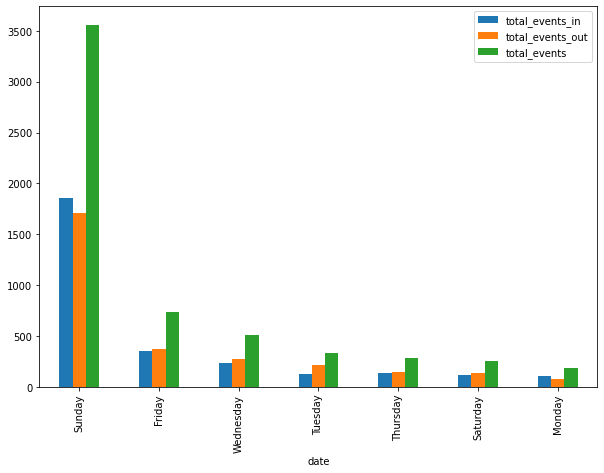

In [12]:
day_of_week_df.plot(kind='bar', figsize=(10, 7))

## Transactions over Days and Hours

In [13]:
day_hour_df = final_df.groupby([final_df['date'].dt.day_name(), final_df['date'].dt.hour])[['total_events_in', 'total_events_out', 'total_events']].sum()

In [14]:
day_hour_df.index.rename(["Day", "Hour"], inplace=True)
day_hour_df.reset_index(inplace=True)

In [15]:
day_hour_df['0 to 8'] = day_hour_df['Hour'] < 9

In [16]:
day_hour_df['9 to 16'] = (day_hour_df['Hour'] > 9) & (day_hour_df['Hour'] < 17)

In [17]:
day_hour_df['17 to 24'] = day_hour_df['Hour'] > 16

In [18]:
day_hour_df.columns

Index(['Day', 'Hour', 'total_events_in', 'total_events_out', 'total_events',
       '0 to 8', '9 to 16', '17 to 24'],
      dtype='object')

In [19]:
day_hour_df.set_index(['Day', 'Hour'], inplace=True)

In [20]:
day_hour_df

total_events_in  total_events_out  total_events  0 to 8  \
Day       Hour                                                            
Friday    2                   6                 7            13    True   
          7                  79                52           131    True   
          8                  26                39            65    True   
          10                 23                44            67   False   
          12                 33                 6            39   False   
          13                 11                18            29   False   
          14                 50                18            68   False   
          19                 10               104           114   False   
          20                118                88           206   False   
          22                  1                 1             2   False   
Monday    0                   5                 2             7    True   
          6                  40                12            52    True   
          8                   0                 2             2    True   
          13                  2                 0             2   False   
          18                 58                50           108   False   
          21                  0                 1             1   False   
          22                  6                11            17   False   
Saturday  0                   9                 0             9    True   
          3                   4                 2             6    True   
          9                   1                 9            10   False   
          10                 24                38            62   False   
          11                 55                69           124   False   
          12                 18                 0            18   False   
          18                  7                20            27   False   
Sunday    0                 207               131           338    True   
          2                  17                 1            18    True   
          3                   4                44            48    True   
          5                  27                24            51    True   
          7                   9                12            21    True   
          8                   4                 0             4    True   
          9                  17                 4            21   False   
          10               1470              1471          2941   False   
          13                 37                 6            43   False   
          14                 24                10            34   False   
          17                  2                 3             5   False   
          18                 35                 2            37   False   
Thursday  5                   3                 4             7    True   
          6                  48                15            63    True   
          14                  0                 2             2   False   
          17                 36                69           105   False   
          19                 27                30            57   False   
          20                  9                13            22   False   
          21                  0                 1             1   False   
          23                 11                12            23   False   
Tuesday   0                   3                 1             4    True   
          8                   3                 5             8    True   
          12                  2                 0             2   False   
          19                 82                93           175   False   
          20                  1                58            59   False   
          21                  5                 2             7   False   
          23                 28                54            82   False   
Wednesday 0                 144          

### Bar Chart for Transactions per Day by Hours (UTC)

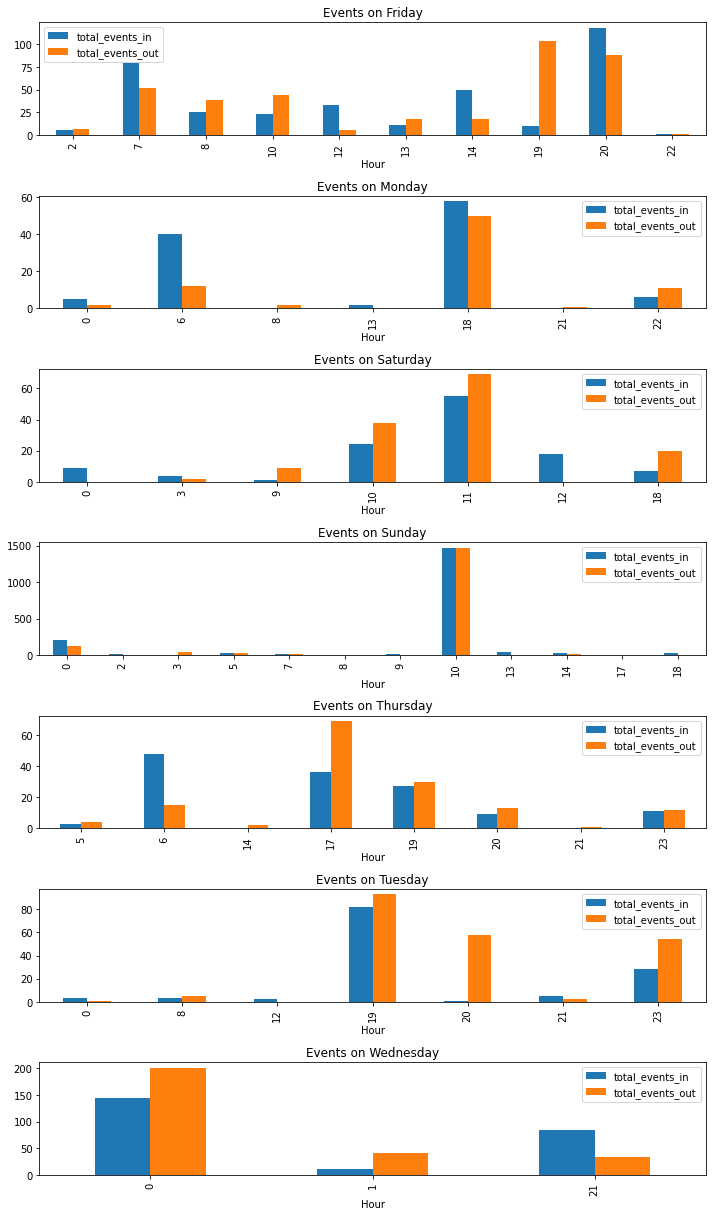

In [21]:
f, a = plt.subplots(nrows=7, ncols=1)

for index, day in enumerate(day_hour_df.index.unique(level=0).tolist()):
    day_hour_df.xs(day)[['total_events_in', 'total_events_out']].plot(kind='bar',ax=a[index], figsize=(10, 17), title="Events on " + day) 
    
f.tight_layout()
plt.show()

### Chart separating Events In/Out and Total over Days and Hours

/usr/local/lib/python3.9/site-packages/pandas/plotting/_matplotlib/tools.py:400: MatplotlibDeprecationWarning: 
The is_first_col function was deprecated in Matplotlib 3.4 and will be removed two minor releases later. Use ax.get_subplotspec().is_first_col() instead.
  if ax.is_first_col():


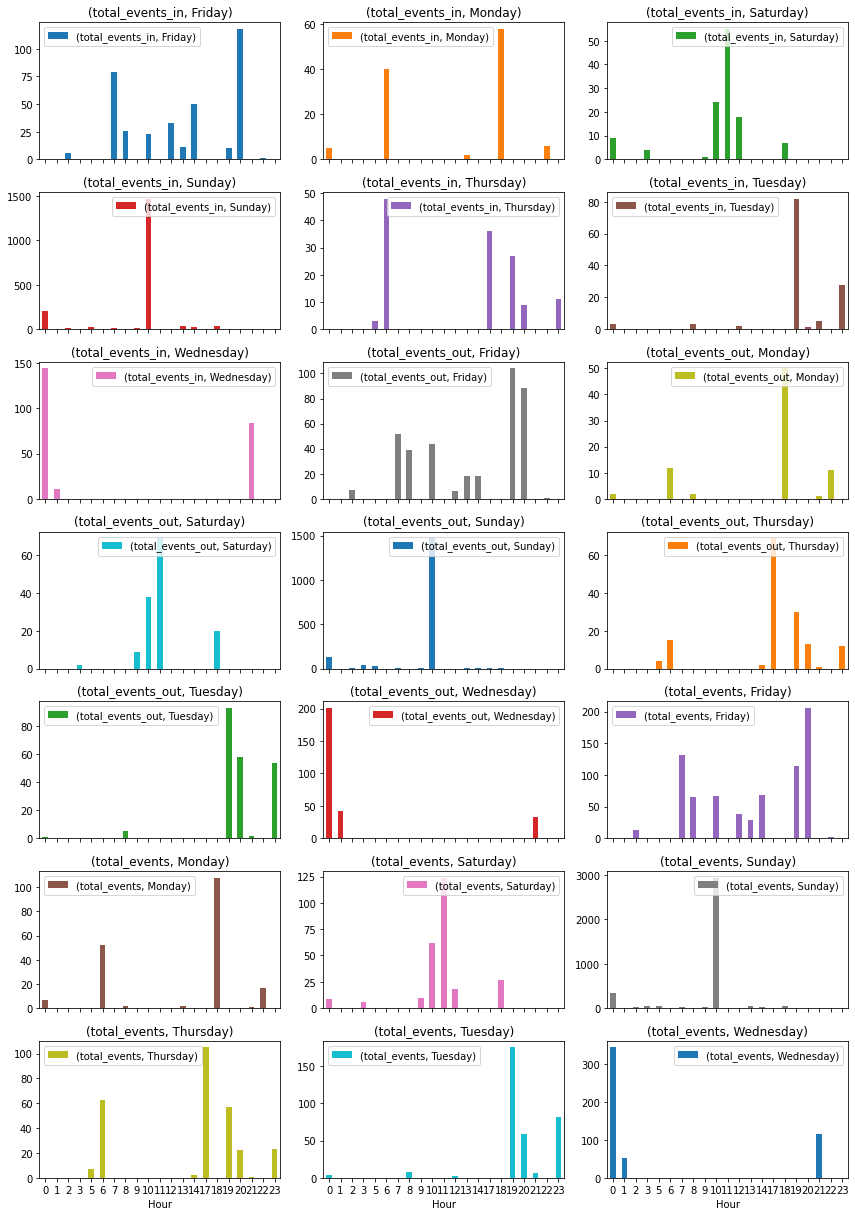

In [22]:
ax = day_hour_df.unstack(level=0).plot(kind='bar', subplots=True, rot=0, figsize=(12, 17), layout=(7, 3))
plt.tight_layout()

In [ ]:
#final_df.to_csv(f"forwarding-history-report.csv", float_format='%.0f', index=False)

# Building Data for Cumulative Sums over Time (Growth Numbers)

In [ ]:
# df['cummulative amount in msat'] = df.groupby(['chan_id_in'])['amt_in_msat'].cumsum()

In [ ]:
df.dtypes

## Grouping In and Out amounts over Time By Channel

In [ ]:
# final_df= final_df.astype({"chan_id":str})
# final_df.drop(final_df.tail(1).index,inplace=True)

In [ ]:
#function for calculating rolling sum
# df, df_chan_age = pr.get_forwarding_history_data("lnd-885")

In [23]:
df['event_date'] = df['event_timestamp'].dt.date

In [24]:
#cummulative sum over days for amount in by channel in
cumsum_in_df = df.groupby(['chan_id_in', 'event_date']).sum().groupby(level=0).cumsum()['amt_in_msat']

#cummulative sum over days for amount in by channel out
cumsum_out_df = df.groupby(['chan_id_out', 'event_date']).sum().groupby(level=0).cumsum()[['amt_out_msat', 'fee_msat']]

In [25]:
#transaction total on the days by chan id in transactions in
in_tx_date = df.groupby(['chan_id_in', 'event_date']).count().groupby(level=0).cumsum()['event_timestamp']
in_tx_date.name = "count_in_tx_cumu"

#transaction total on the days by chan id in transactions out
out_tx_date = df.groupby(['chan_id_out', 'event_date']).count().groupby(level=0).cumsum()['event_timestamp']
out_tx_date.name = "count_out_tx_cumu"

In [26]:
in_tx_over_days = pd.concat([cumsum_in_df, in_tx_date], axis=1)

In [27]:
out_tx_over_days = pd.concat([cumsum_out_df, out_tx_date], axis=1)

In [28]:
#get average forward size per day for out transactions
avg_out_amt = out_tx_over_days['amt_out_msat']/out_tx_over_days['count_out_tx_cumu']
avg_out_amt.name = "avg_out_amt"

In [29]:
#get average incoming size per day for in transactions
avg_in_amt = in_tx_over_days['amt_in_msat']/in_tx_over_days['count_in_tx_cumu']
avg_in_amt.name = "avg_in_amt"

In [30]:
in_tx_over_days = pd.concat([in_tx_over_days, avg_in_amt], axis=1)

In [31]:
out_tx_over_days = pd.concat([out_tx_over_days, avg_out_amt], axis=1)

In [32]:
tx_over_days = pd.concat([in_tx_over_days, out_tx_over_days], axis=1).fillna(method='ffill')

In [33]:
tmp_df = tx_over_days.reset_index()

In [34]:
tmp_df.rename(columns={'level_0':'chan_id'}, inplace=True)
tmp_df.set_index('chan_id', inplace=True)

In [35]:
tmp_df['count_tx_cumu'] = tmp_df['count_in_tx_cumu']+tmp_df['count_out_tx_cumu']

In [36]:
tmp_df[['amt_in_msat', 'avg_in_amt', 'amt_out_msat', 'avg_out_amt', 'fee_msat', 'count_in_tx_cumu', 'count_out_tx_cumu', 'count_tx_cumu']]

,amt_in_msat,avg_in_amt,amt_out_msat,avg_out_amt,fee_msat,count_in_tx_cumu,count_out_tx_cumu,count_tx_cumu
chan_id,,,,,,,,
781839628895059970,2028004,1014002,NaN,NaN,NaN,2,NaN,NaN
781839628895059970,553093903,184364634,NaN,NaN,NaN,3,NaN,NaN
781839628895059970,592057941,148014485,201443491,201443491,1201,4,1,5
781839628895059970,1003050344,52792123,775578639,193894660,4775,19,4,23
781839628895059970,1056251396,50297686,975601038,195120208,5975,21,5,26
...,...,...,...,...,...,...,...,...
792540076034097153,490115968,70016567,922704345,65907453,14922,7,14,21
792540076034097153,1142908461,126989829,922704345,65907453,14922,9,14,23
792687410604212225,372489313,186244656,922704345,65907453,14922,2,14,16


## Example Plots for Cumulative Values over Time for a Single Channel

In [ ]:
tmp_df.loc[781839628895059970][['event_date', 'amt_in_msat', 'avg_in_amt', 'amt_out_msat', 'avg_out_amt', 'fee_msat', 'count_in_tx_cumu', 'count_out_tx_cumu', 'count_tx_cumu']]\
    .plot(x='event_date', subplots=True, figsize=(25,10), layout=(2,4))

# Data for All Channels Grouped - Cumulative Sum over Time

In [ ]:
#cummulative sum over days for amount in by channel in
cumsum_df = df.groupby(['event_date'])[['amt_in_msat', 'amt_out_msat', 'fee_msat']].sum().apply(lambda x: x.cumsum())

In [ ]:
#transaction total on the days by chan id in transactions in
cumsum_tx_date = df.groupby(['event_date']).count().groupby(level=0).sum().apply(lambda x: x.cumsum())['fee_msat']
cumsum_tx_date.name = "count_tx_cumu"

In [ ]:
all_tx_over_days = pd.concat([cumsum_df, cumsum_tx_date], axis=1)

In [ ]:
#get average forward size per day for out transactions
avg_out_amt = all_tx_over_days['amt_out_msat']/all_tx_over_days['count_tx_cumu']
avg_out_amt.name = "avg_out_amt"

In [ ]:
#get average incoming size per day for in transactions
avg_in_amt = all_tx_over_days['amt_in_msat']/all_tx_over_days['count_tx_cumu']
avg_in_amt.name = "avg_in_amt"

In [ ]:
all_tx_over_days = pd.concat([all_tx_over_days, avg_in_amt], axis=1)

In [ ]:
all_tx_over_days = pd.concat([all_tx_over_days, avg_out_amt], axis=1)

## Example Plot for Cumulative Values over Time for All Channels (or the single Node)

In [ ]:
all_tx_over_days.columns

In [ ]:
all_tx_over_days[['amt_in_msat', 'avg_in_amt', 'fee_msat', 'amt_out_msat', 'avg_out_amt', 'count_tx_cumu']].plot(subplots=True, figsize=(20,10), layout=(2,3), rot=45)

In [ ]:
pd.set_option('display.float_format', lambda x: '%.f' % x)

# tx_over_days.pct_change(axis=0, periods=1)

## Building Perecentage Representations for Week over Week Growth 

In [39]:
#add sums for amt_in, fees for week over week
growth_df_in = df.groupby(['chan_id_in', 'event_date']).sum().reset_index()

In [81]:
#loop in increments of weeks to end date to build change values per cahnnel for amt in
end_date = pd.to_datetime(date.today(), utc=True)
tmp_date1 = df['event_date'].min()

amt_in_wkly = pd.DataFrame(growth_df_in[growth_df_in['event_date'] <= df['event_date'].min()+pd.to_timedelta(7, unit='d')].groupby(['chan_id_in']).sum()['amt_in_msat'])

for i in range(1, round((df['event_date'].max() - df['event_date'].min()).days/7)+1):
    tmp_date = df['event_date'].min()+pd.to_timedelta(i*7, unit='d')
    tmp_date2 = df['event_date'].min()+pd.to_timedelta((i+1)*7, unit='d')
    if tmp_date2 > end_date:
        tmp_date2 = end_date
        
    amt_in_wkly = pd.merge(amt_in_wkly, growth_df_in[(growth_df_in['event_date'] > tmp_date) & (growth_df_in['event_date'] <= tmp_date2)].groupby(['chan_id_in']).sum()['amt_in_msat'], on=['chan_id_in'], how='outer').rename(columns={'amt_in_msat_x': f'wk{i}_amt_in', 'amt_in_msat_y':f'wk{i+1}_amt_in'})


In [116]:
#add sums for amt_in, fees for week 1 week 2 week 3 week 4
growth_df_out = df.groupby(['chan_id_out', 'event_date']).sum().reset_index()

In [118]:
growth_df_out

,chan_id_out,event_date,chan_id_in,amt_in,amt_out,fee,fee_msat,amt_in_msat,amt_out_msat,timestamp_ns
0,781839628895059970,2021-12-17,785255811538550784,201444,201443,1,1201,201444692,201443491,1639751473649081600
1,781839628895059970,2021-12-18,2354751485836591104,574137,574134,3,3574,574138722,574135148,4919479014915303424
2,781839628895059970,2021-12-19,785372359798292480,200023,200022,1,1200,200023599,200022399,1639888765396448768
3,781839628895059970,2021-12-22,4711302872290426880,600021,600015,6,6600,600022846,600016246,9841170199309854720
4,781839628895059970,2021-12-23,4718043977917530112,1000007,1000000,6,6996,1000008106,1000001110,9841714712080168960
...,...,...,...,...,...,...,...,...,...,...
416,792381746322538496,2022-01-29,9493900277090615296,700182,700170,12,12700,700187700,700175000,19721483139806003200
417,792381746322538496,2022-01-30,790651114986668032,100052,100050,1,1100,100052000,100050900,1643583490762357504
418,792381746322538496,2022-01-31,790504880040378368,122479,122478,1,1122,122479567,122478445,1643643769399718400
419,792762177405648896,2022-01-30,7888568220089516032,1898159,1898148,11,11895,1898165428,1898153533,16435456040856850432


In [119]:
#loop in increments of weeks to end date to build change values per cahnnel for amt in
end_date = pd.to_datetime(date.today(), utc=True)
tmp_date1 = df['event_date'].min()

amt_out_wkly = pd.DataFrame(growth_df_out[growth_df_out['event_date'] <= df['event_date'].min()+pd.to_timedelta(7, unit='d')].groupby(['chan_id_out']).sum()[['amt_out_msat', 'fee_msat']])

for i in range(1, round((df['event_date'].max() - df['event_date'].min()).days/7)+1):
    tmp_date = df['event_date'].min()+pd.to_timedelta(i*7, unit='d')
    tmp_date2 = df['event_date'].min()+pd.to_timedelta((i+1)*7, unit='d')
    if tmp_date2 > end_date:
        tmp_date2 = end_date
        
    amt_out_wkly = pd.merge(amt_out_wkly, growth_df_out[(growth_df_out['event_date'] > tmp_date) & (growth_df_out['event_date'] <= tmp_date2)].groupby(['chan_id_out']).sum()[['amt_out_msat', 'fee_msat']], on=['chan_id_out'], how='outer')\
    .rename(columns={'amt_out_msat_x': f'wk{i}_amt_out', 'amt_out_msat_y':f'wk{i+1}_amt_out', 'fee_msat_x' : f'wk{i}_fee_msat', 'fee_msat_y' : f'wk{i+1}_fee_msat'})


In [ ]:
#Plot amount out week over week for total
fig, ax = plt.subplots(figsize=(15,10))
amt_in_wkly.sum()[:-1].plot()
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [131]:
fee_columns = [s for s in amt_out_wkly.columns if "fee" in s]
amt_out_columns = [s for s in amt_out_wkly.columns if "out" in s]

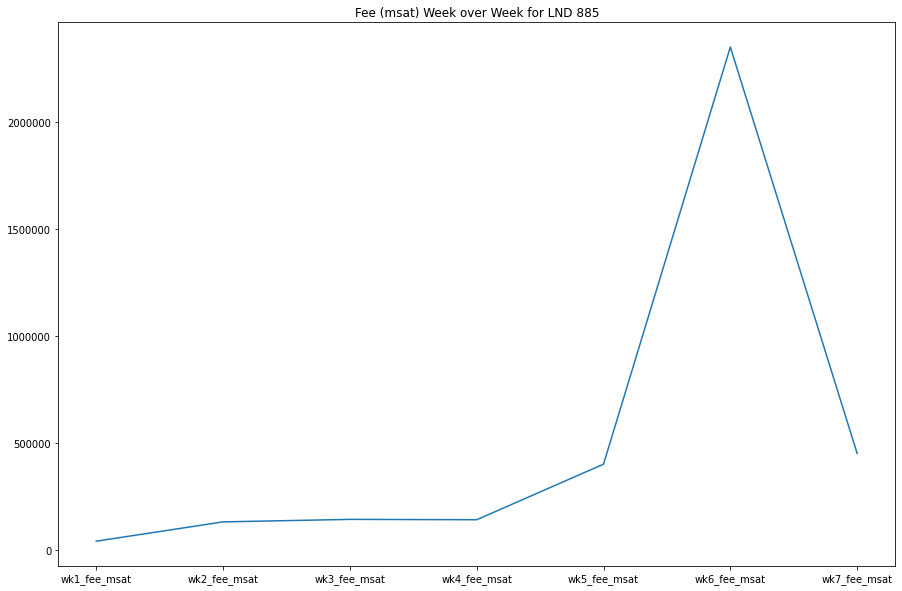

In [139]:
#Plot fee breakdown week over week for total
fig, ax = plt.subplots(figsize=(15,10))
amt_out_wkly[fee_columns].sum()[:-1].plot()
plt.ticklabel_format(style='plain', axis='y')
plt.title("Fee (msat) Week over Week for LND 885")
plt.show()

In [143]:
amt_out_wkly[fee_columns].sum()

wk1_fee_msat     41188
wk2_fee_msat    131316
wk3_fee_msat    143055
wk4_fee_msat    141355
wk5_fee_msat    400710
wk6_fee_msat   2348833
wk7_fee_msat    450935
wk8_fee_msat     55815
dtype: float64

In [153]:
amt_out_wkly[amt_out_columns].sum()

wk1_amt_out     7201961803
wk2_amt_out    15365244368
wk3_amt_out    30091654904
wk4_amt_out    25368718652
wk5_amt_out    55737767457
wk6_amt_out    84658226761
wk7_amt_out   131024783628
wk8_amt_out     9829584973
dtype: float64

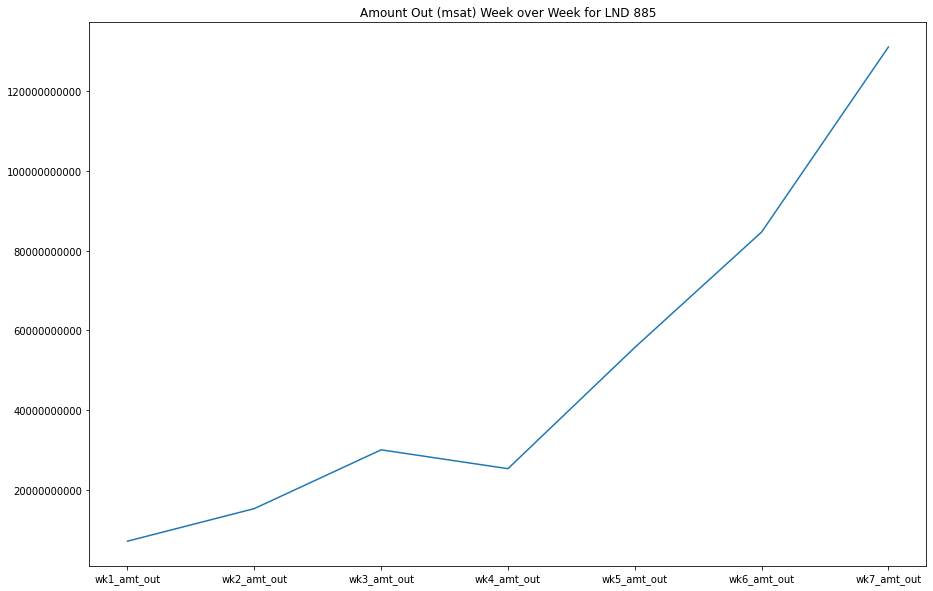

In [140]:
#Plot amount out breakdown week over week for total
fig, ax = plt.subplots(figsize=(15,10))
amt_out_wkly[amt_out_columns].sum()[:-1].plot()
plt.ticklabel_format(style='plain', axis='y')
plt.title("Amount Out (msat) Week over Week for LND 885")
plt.show()

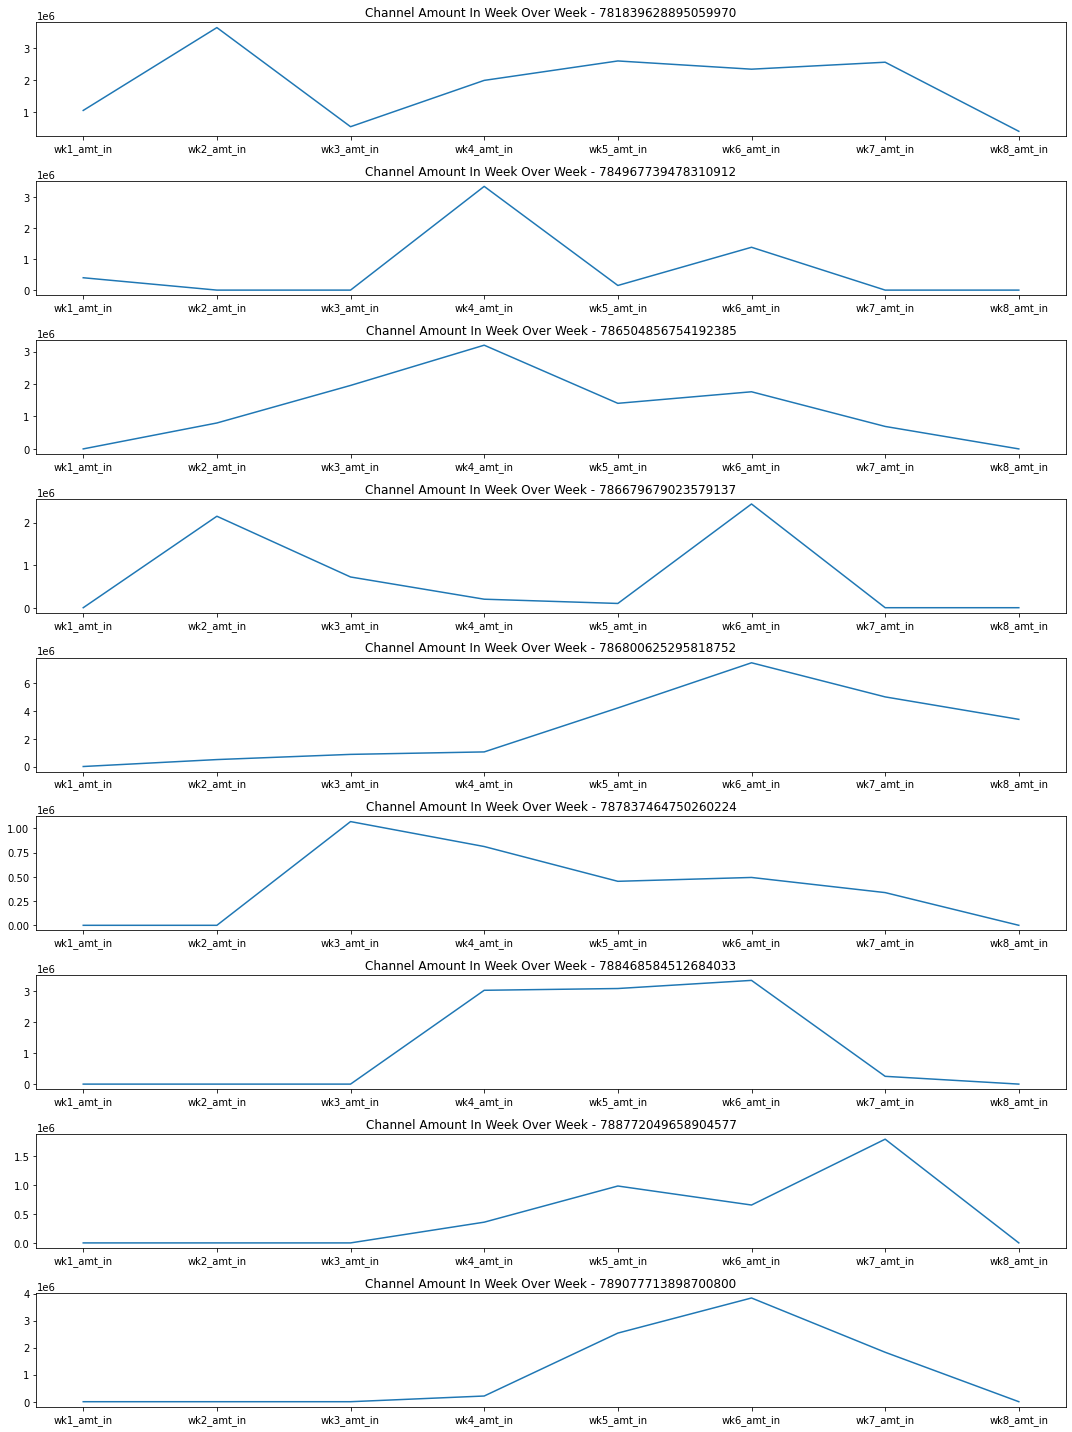

In [115]:
f, a = plt.subplots(len(tmp_amt_in_wkly.index.unique()), figsize=(15,20))

# for index, day in enumerate(day_hour_df.index.unique(level=0).tolist()):
#     day_hour_df.xs(day)[['total_events_in', 'total_events_out']].plot(kind='bar',ax=a[index], figsize=(10, 17), title="Events on " + day) 


for index, chan_id in enumerate(tmp_amt_in_wkly.index.unique()):
    a[index].set_title("Channel Amount In Week Over Week - " + str(chan_id))
    a[index].plot(tmp_amt_in_wkly.loc[chan_id])
    
    
f.tight_layout()
plt.show()

In [ ]:
growth_df[growth_df['event_date'] <= week1].groupby(['chan_id_in']).sum()

In [ ]:
df[df['event_date'] < week_from_start].groupby(['chan_id_in']).sum()['amt_in']

In [ ]:
# df_total_events_out = df[['chan_id_out', 'lnd_node']].value_counts().to_frame("total_events_out")
df.groupby(['chan_id_in','event_date']).

In [7]:
bg = buildGrowthReport(df, ".", True)

In [14]:
bg.build_growth_df()

,amt_in,amt_out,fees_msat
week1,7202002991,7201961803,41188
week2,15365375684,15365244368,131316
week3,30091797959,30091654904,143055
week4,25368860007,25368718652,141355
week5,55738168167,55737767457,400710
week6,84660575594,84658226761,2348833
week7,131025234563,131024783628,450935
week8,9829640788,9829584973,55815


wk1_amt_out     7201961803
wk2_amt_out    15365244368
wk3_amt_out    30091654904
wk4_amt_out    25368718652
wk5_amt_out    55737767457
wk6_amt_out    84658226761
wk7_amt_out   131024783628
wk8_amt_out     9829584973
Name: amt_out, dtype: float64

In [ ]:
bg.amt_out_growth().sum()
pd.DataFrame(pd.concat(bg.amt_in_growth().sum(),bg.amt_out_growth().sum()), columns=['amt_in', 'amt_out'])

In [ ]:
#build dataframe with all transactions for cummulative sum over time
# Get Average Forward Sizes


In [ ]:
# Breakdown the total Amounts over time to show the increase over time


# Adding LND Node Total Capacity and Channel Capacity

In [ ]:
# Get Channel Capacity

In [150]:
df.sum()

chan_id_in                                   -5567015235490413763
chan_id_out                                  -5211225367396351272
amt_in                                                  359281155
amt_out                                                 359277515
fee                                                          3489
fee_msat                                                  3713207
amt_in_msat                                          359281655753
amt_out_msat                                         359277942546
timestamp_ns                                 -5685803301622584550
lnd_node        lnd-885lnd-885lnd-885lnd-885lnd-885lnd-885lnd-...
dtype: object

In [16]:
#channel capacity
f_channels = open("listchannels_Jan31_2022.txt")
channel_json = json.load(f_channels)
# forwarding_history = importFH.handle_forwarding_history_json(rpc_json_res, args.lnd)
# importFH.insert_forwarding_history(forwarding_history)

In [38]:
(datetime.now() - timedelta(seconds=47810)).timestamp()*1000

1643909607459.985

In [2]:
channel_json['channels'][0]

NameError: name 'channel_json' is not defined

In [93]:
f_tx = open("/Users/jjackson/LQwD/chainTXs_lnd885_Jan27_2022.txt")
txs = json.load(f_tx)

In [96]:
txs['transactions'][0]

{'tx_hash': '752b4b1226be5e9abf619b6e990c023f0c4d495c69f2db4619251820b4977425',
 'amount': '0',
 'num_confirmations': 0,
 'block_hash': '',
 'block_height': 0,
 'time_stamp': '1642539273',
 'total_fees': '0',
 'dest_addresses': ['bc1qqq85vyaytwcz5cgyuhml0u3yg0k27kumggvfmf'],
 'raw_tx_hex': '020000000001011fe59a45f5f59d8e55dbceca4a045b7991314eac3f94d4c39c38f0c158f6931a0100000000ffffffff01d892980000000000160014000f4613a45bb02a6104e5f7f7f22443ecaf5b9b040047304402201fa678e8e09d267ea752809db2433211420cc176a67198c4198c795a2607116a022041899bb743f933f8f847174aae578bca3727bffee6d55bd2b43eb067a156a920014730440220118ee09e147657a70805a4d8adc71034d463a669e1b97bf50188c1fcb2c3724d02202cf93c96a74ed3ab69fda09c158f50cf791aeda0b09aa8e911bb682621c21c470147522102db3e08970cf9f74daaa7247dcd41564102af7251956318eae5a835a204fdc6c521032537c81c9be07997f2b8cf09b14ccc0ab5ec1aa246fb17b295206e1d0ced6e6d52ae00000000',
 'label': '0:closechannel:shortchanid-790822638947860481'}

In [136]:
tx_open_list = list()
tx_close_list = list()

for tx in txs['transactions']:
    if "openchannel" in tx['label']:
        tx_open_list.append((tx['tx_hash'], tx['total_fees'], tx['amount'], tx['time_stamp']))
    if "closechannel" in tx['label']:
        tx_close_list.append((tx['tx_hash'], tx['total_fees'], tx['amount'], tx['time_stamp']))

In [137]:
tx_close_df = pd.DataFrame(tx_close_list, columns=['hash', 'tx_fees', 'amount', 'timestamp'])

In [138]:
tx_open_df = pd.DataFrame(tx_open_list, columns=['hash', 'tx_fees', 'amount', 'timestamp'])

In [139]:
tx_open_df = tx_open_df.astype({'hash': 'string', 'tx_fees': 'int32', 'amount': 'int32', 'timestamp': 'int32'})
tx_close_df = tx_close_df.astype({'hash': 'string', 'tx_fees': 'int32', 'amount': 'int32', 'timestamp': 'int32'})

In [140]:
tx_open_df['date'] = pd.to_datetime(tx_open_df['timestamp'], unit='s', utc=True)
tx_close_df['date'] = pd.to_datetime(tx_close_df['timestamp'], unit='s', utc=True)

In [144]:
tx_open_df.sort_values(by='date').to_csv("openchannel_tx.csv")

In [145]:
tx_close_df.sort_values(by='date').to_csv("closechannel_tx.csv")

In [142]:
tx_open_df.sum()

tx_fees            32309
amount        -214195557
timestamp    73819504610
dtype: int64

In [143]:
tx_close_df.sort_values(by='date').sum()

tx_fees                0
amount          16842367
timestamp    21341962669
dtype: int64